# Codificación de Huffman

Compresión sin pérdida que asigna códigos binarios más cortos a los símbolos más frecuentes. Se construye un árbol uniendo repetidamente los dos nodos de menor frecuencia (con una cola de prioridad); el camino hasta cada hoja (0 = izquierda, 1 = derecha) es su código. Ningún código es prefijo de otro, así que la decodificación no es ambigua.

## 1. Tabla de códigos

Construir el árbol de Huffman de un texto con `heapq` y obtener el código de cada carácter.

In [1]:
import heapq
from collections import Counter
from itertools import count

def codigos_huffman(texto):
    desempate = count()
    # (frecuencia, desempate, árbol); hoja = carácter, nodo = (izq, der)
    cola = [(f, next(desempate), c) for c, f in Counter(texto).items()]
    heapq.heapify(cola)
    while len(cola) > 1:
        f1, _, a = heapq.heappop(cola)
        f2, _, b = heapq.heappop(cola)
        heapq.heappush(cola, (f1 + f2, next(desempate), (a, b)))

    codigos = {}
    def recorre(nodo, codigo):
        if isinstance(nodo, str):
            codigos[nodo] = codigo or "0"
        else:
            recorre(nodo[0], codigo + "0")
            recorre(nodo[1], codigo + "1")
    recorre(cola[0][2], "")
    return codigos

texto = "abracadabra"
codigos = codigos_huffman(texto)
print(codigos)

{'a': '0', 'c': '100', 'd': '101', 'b': '110', 'r': '111'}


## 2. Codificar y decodificar

Codificar un texto con la tabla, decodificarlo leyendo bit a bit y comparar el tamaño con 8 bits por carácter.

In [2]:
def codifica(texto, codigos):
    return "".join(codigos[c] for c in texto)

def decodifica(bits, codigos):
    inverso = {v: k for k, v in codigos.items()}
    resultado, actual = [], ""
    for bit in bits:
        actual += bit
        if actual in inverso:
            resultado.append(inverso[actual])
            actual = ""
    return "".join(resultado)

texto = "en un lugar de la mancha de cuyo nombre no quiero acordarme"
codigos = codigos_huffman(texto)
bits = codifica(texto, codigos)
assert decodifica(bits, codigos) == texto
print(f"{len(texto) * 8} bits -> {len(bits)} bits ({len(bits) / (len(texto) * 8):.0%})")

472 bits -> 222 bits (47%)


## 3. Comparar con longitud fija y con la entropía

Para varios textos, comparar los bits por carácter de Huffman con los de un código de longitud fija ($\lceil \log_2 k \rceil$ bits para $k$ símbolos distintos), con los 8 bits de ASCII y con la entropía de Shannon $H = -\sum p_i \log_2 p_i$, que es el mínimo teórico. Comprobar que la longitud media $\bar{L}$ de Huffman cumple $H \le \bar{L} < H + 1$ y dibujarlo en un gráfico de barras.

abracadabra  H = 2.040  Huffman = 2.091  fija = 3  tasa frente a ASCII = 26%
sesgado      H = 1.490  Huffman = 1.550  fija = 2  tasa frente a ASCII = 19%
uniforme     H = 2.991  Huffman = 3.000  fija = 3  tasa frente a ASCII = 38%
castellano   H = 3.955  Huffman = 4.006  fija = 5  tasa frente a ASCII = 50%


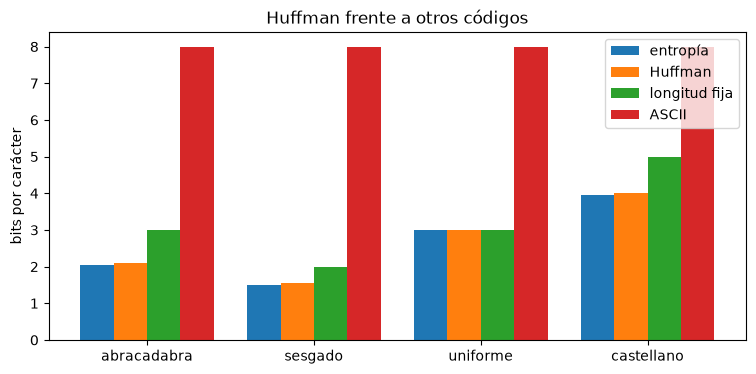

In [3]:
import math
import random
import matplotlib.pyplot as plt

def entropia(texto):
    n = len(texto)
    return -sum(f / n * math.log2(f / n) for f in Counter(texto).values())

random.seed(6)
textos = {
    "abracadabra": "abracadabra",
    "sesgado": "a" * 60 + "b" * 25 + "c" * 10 + "d" * 5,
    "uniforme": "".join(random.choice("abcdefgh") for _ in range(400)),
    "castellano": "en un lugar de la mancha de cuyo nombre no quiero acordarme no ha mucho tiempo que vivia "
                  "un hidalgo de los de lanza en astillero adarga antigua rocin flaco y galgo corredor",
}
filas = {}
for nombre, t in textos.items():
    cod = codigos_huffman(t)
    media = len(codifica(t, cod)) / len(t)
    fija = math.ceil(math.log2(len(cod))) if len(cod) > 1 else 1
    H = entropia(t)
    assert H <= media < H + 1 and media <= fija
    filas[nombre] = (H, media, fija, 8)
    print(f"{nombre:12} H = {H:.3f}  Huffman = {media:.3f}  fija = {fija}  tasa frente a ASCII = {media / 8:.0%}")

fig, eje = plt.subplots(figsize=(9, 4))
etiquetas = ["entropía", "Huffman", "longitud fija", "ASCII"]
for k, etiqueta in enumerate(etiquetas):
    eje.bar([x + (k - 1.5) * 0.2 for x in range(len(filas))], [f[k] for f in filas.values()], 0.2, label=etiqueta)
eje.set_xticks(range(len(filas)), filas.keys())
eje.set(ylabel="bits por carácter", title="Huffman frente a otros códigos")
eje.legend()
plt.show()

## 4. Código canónico

Para guardar un código de Huffman basta con la longitud de cada código: el código canónico ordena los símbolos por (longitud, símbolo) y les asigna números binarios consecutivos, añadiendo ceros a la derecha cada vez que crece la longitud. Construirlo a partir de las longitudes de Huffman y comprobar que tiene las mismas longitudes (y por tanto comprime igual), que ningún código es prefijo de otro y que cumple la igualdad de Kraft $\sum 2^{-\ell_i} = 1$.

In [4]:
def codigo_canonico(longitudes):
    codigos, valor, anterior = {}, 0, 0
    for simbolo, l in sorted(longitudes.items(), key=lambda par: (par[1], par[0])):
        valor <<= l - anterior
        codigos[simbolo] = format(valor, f"0{l}b")
        valor, anterior = valor + 1, l
    return codigos

def es_libre_de_prefijos(codigos):
    ordenados = sorted(codigos.values())
    return all(not b.startswith(a) for a, b in zip(ordenados, ordenados[1:]))

for t in list(textos.values()) + ["".join(random.choice("abcdefghijklmnop") for _ in range(random.randint(2, 300)))
                                  for _ in range(200)]:
    huffman = codigos_huffman(t)
    if len(huffman) < 2:
        continue
    canonico = codigo_canonico({s: len(c) for s, c in huffman.items()})
    assert {s: len(c) for s, c in canonico.items()} == {s: len(c) for s, c in huffman.items()}
    assert es_libre_de_prefijos(canonico) and es_libre_de_prefijos(huffman)
    assert sum(2 ** -len(c) for c in canonico.values()) == 1
    assert decodifica(codifica(t, canonico), canonico) == t

huffman = codigos_huffman(textos["castellano"])
canonico = codigo_canonico({s: len(c) for s, c in huffman.items()})
for s in sorted(canonico, key=lambda s: (len(canonico[s]), s))[:8]:
    print(repr(s), huffman[s], "->", canonico[s])

' ' 111 -> 000
'a' 011 -> 001
'o' 000 -> 010
'd' 0010 -> 0110
'e' 1011 -> 0111
'i' 0011 -> 1000
'l' 0101 -> 1001
'n' 1001 -> 1010


## 5. Comprimir a bytes y decodificar con un árbol

Escribir el texto comprimido como `bytes`: una cabecera con el número de símbolos y, para cada uno, su carácter y la longitud de su código, seguida del número de bits y los bits empaquetados. Para descomprimir, reconstruir el código canónico desde las longitudes, montar con él un árbol (un diccionario por nodo) y recorrerlo bit a bit. Comparar el tamaño con el texto original y comprobar la ida y vuelta.

In [5]:
def comprime(texto):
    canonico = codigo_canonico({s: len(c) for s, c in codigos_huffman(texto).items()})
    bits = codifica(texto, canonico)
    cabecera = bytes([len(canonico)]) + b"".join(s.encode("latin-1") + bytes([len(c)]) for s, c in canonico.items())
    datos = int("1" + bits, 2).to_bytes((len(bits) + 8) // 8)  # el 1 inicial conserva los ceros de delante
    return cabecera + len(bits).to_bytes(4) + datos

def descomprime(datos):
    k, longitudes, i = datos[0], {}, 1
    for _ in range(k):
        longitudes[chr(datos[i])] = datos[i + 1]
        i += 2
    n_bits = int.from_bytes(datos[i:i + 4])
    bits = bin(int.from_bytes(datos[i + 4:]))[3:]
    assert len(bits) == n_bits
    arbol = {}
    for simbolo, codigo in codigo_canonico(longitudes).items():
        nodo = arbol
        for bit in codigo[:-1]:
            nodo = nodo.setdefault(bit, {})
        nodo[codigo[-1]] = simbolo
    resultado, nodo = [], arbol
    for bit in bits:
        nodo = nodo[bit]
        if isinstance(nodo, str):
            resultado.append(nodo)
            nodo = arbol
    return "".join(resultado)

for nombre, t in textos.items():
    comprimido = comprime(t)
    assert descomprime(comprimido) == t
    print(f"{nombre:12} {len(t):4} bytes -> {len(comprimido):4} bytes ({len(comprimido) / len(t):.0%})")

for _ in range(200):
    t = "".join(random.choice("abcdefghij ") for _ in range(random.randint(2, 500)))
    if len(set(t)) > 1:
        assert descomprime(comprime(t)) == t

abracadabra    11 bytes ->   18 bytes (164%)
sesgado       100 bytes ->   33 bytes (33%)
uniforme      400 bytes ->  172 bytes (43%)
castellano    172 bytes ->  138 bytes (80%)
